# 1. Detector: train, evaluate, compress, benchmark, robustness
YOLOv8n on VisDrone-DET. Outputs go to `reports/`.

In [1]:
import time, shutil, numpy as np, pandas as pd, cv2, onnxruntime as ort, matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO
Path('reports').mkdir(exist_ok=True)
RUN = Path('runs/v8n_640_s0'); BEST = RUN/'weights/best.pt'
from ultralytics import settings
settings.update({'datasets_dir': str(Path('data').resolve())})   # keep datasets inside this folder

## Train (skipped if `best.pt` exists)
50 epochs, imgsz 640, batch 16 (AutoBatch picked 3 on this 6 GB GPU), one seed.

In [2]:
if not BEST.exists():
    YOLO('yolov8n.pt').train(data='VisDrone.yaml', epochs=50, imgsz=640, batch=16, workers=4,
                             seed=0, patience=15, project='runs', name='v8n_640_s0')

## Per-class mAP: PyTorch (GPU)

In [3]:
def evaluate(weights, tag, device):
    r = YOLO(weights, task='detect').val(data='VisDrone.yaml', imgsz=640, device=device, plots=False, verbose=False)
    names = r.names
    df = pd.DataFrame({'model': tag, 'class': [names[i] for i in r.box.ap_class_index],
                       'map50': r.box.ap50, 'map50_95': r.box.maps[r.box.ap_class_index]})
    return pd.concat([df, pd.DataFrame([{'model': tag, 'class': 'all', 'map50': r.box.map50, 'map50_95': r.box.map}])])

metrics = [evaluate(BEST, 'pytorch', 0)]
metrics[0]

Ultralytics 8.4.212  Python-3.11.9 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)


Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 1178.2±550.8 MB/s, size: 139.6 KB)


val: Scanning D:\Projects\computer-vision project\data\VisDrone\labels\val... 1 images, 0 backgrounds, 0 corrupt: 0% ──────────── 1/548 2.3it/s 0.1s<3:56

val: Scanning D:\Projects\computer-vision project\data\VisDrone\labels\val... 223 images, 0 backgrounds, 0 corrupt: 40% ━━━━╸─────── 223/548 641.0it/s 0.2s<0.5s

val: Scanning D:\Projects\computer-vision project\data\VisDrone\labels\val... 331 images, 0 backgrounds, 0 corrupt: 60% ━━━━━━━───── 331/548 758.4it/s 0.3s<0.3s

... (31 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 1.5it/s 22.9s

                   all        548      38759      0.443      0.325      0.306       0.17


Speed: 0.6ms preprocess, 2.2ms inference, 0.0ms loss, 1.9ms postprocess per image


,model,class,map50,map50_95
0,pytorch,pedestrian,0.320123,0.126880
1,pytorch,people,0.236920,0.078793
2,pytorch,bicycle,0.074346,0.027005
3,pytorch,car,0.727591,0.475524
4,pytorch,van,0.344788,0.231230
5,pytorch,truck,0.285359,0.183525
6,pytorch,tricycle,0.198247,0.102318
7,pytorch,awning-tricycle,0.110746,0.066743
8,pytorch,bus,0.428574,0.276461
9,pytorch,motor,0.332568,0.126579


## Export ONNX (fp32 and INT8) and evaluate on CPU

In [4]:
W = RUN/'weights'
m = YOLO(BEST)
shutil.copy(m.export(format='onnx', imgsz=640), W/'best_fp32.onnx')
m.export(format='onnx', imgsz=640, quantize=8, data='VisDrone.yaml', fraction=0.5)   # writes best_int8.onnx
for tag in ['fp32', 'int8']:
    metrics.append(evaluate(W/f'best_{tag}.onnx', f'onnx_{tag}', 'cpu'))
det_df = pd.concat(metrics); det_df.to_csv('reports/detector_metrics.csv', index=False)
det_df.pivot(index='class', columns='model', values='map50_95')

Ultralytics 8.4.212  Python-3.11.9 torch-2.14.1+cu126 CPU (AMD Ryzen 9 5900HS with Radeon Graphics)


Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs



PyTorch: starting from 'runs\v8n_640_s0\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 14, 8400) (6.2 MB)



ONNX: starting export with onnx 1.23.2 opset 18...


ONNX: slimming with onnxslim 0.1.99...


ONNX: export success  1.1s, saved as 'runs\v8n_640_s0\weights\best.onnx' (12.2 MB)


... (584 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 548/548 11.8it/s 46.5s

                   all        548      38759      0.408      0.322      0.291      0.158


Speed: 1.0ms preprocess, 59.6ms inference, 0.0ms loss, 11.5ms postprocess per image


model,onnx_fp32,onnx_int8,pytorch
class,,,
all,0.169426,0.158361,0.169506
awning-tricycle,0.064310,0.056253,0.066743
bicycle,0.027603,0.022082,0.027005
bus,0.279938,0.272225,0.276461
car,0.475337,0.452587,0.475524
motor,0.127240,0.112163,0.126579
pedestrian,0.125897,0.113458,0.126880
people,0.078730,0.074284,0.078793
tricycle,0.102283,0.084999,0.102318


## CPU latency (batch 1, 4 threads, 20 warm-up + 200 timed) and accuracy-vs-latency chart
Run with other apps closed and the laptop plugged in.

In [5]:
import platform, torch
def bench_ort(path, n=200, warm=20):
    so = ort.SessionOptions(); so.intra_op_num_threads = 4; so.inter_op_num_threads = 1
    s = ort.InferenceSession(str(path), so, providers=['CPUExecutionProvider'])
    x = np.random.rand(1, 3, 640, 640).astype(np.float32)
    return lambda: s.run(None, {s.get_inputs()[0].name: x})

torch.set_num_threads(4)
net = YOLO(BEST).model.cpu().eval(); xt = torch.rand(1, 3, 640, 640)
def run_torch():
    with torch.no_grad(): net(xt)

fns = {'pytorch': run_torch, 'onnx_fp32': bench_ort(W/'best_fp32.onnx'), 'onnx_int8': bench_ort(W/'best_int8.onnx')}
lat = {}
for k, f in fns.items():
    for _ in range(20): f()
    t = []
    for _ in range(200):
        a = time.perf_counter(); f(); t.append((time.perf_counter() - a) * 1000)
    lat[k] = {'median_ms': np.median(t), 'p95_ms': np.percentile(t, 95)}
lat = pd.DataFrame(lat).T; lat.to_csv('reports/latency.csv'); print(platform.processor()); lat

AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD


,median_ms,p95_ms
pytorch,52.51145,57.384475
onnx_fp32,31.04435,32.312635
onnx_int8,55.01055,57.958845


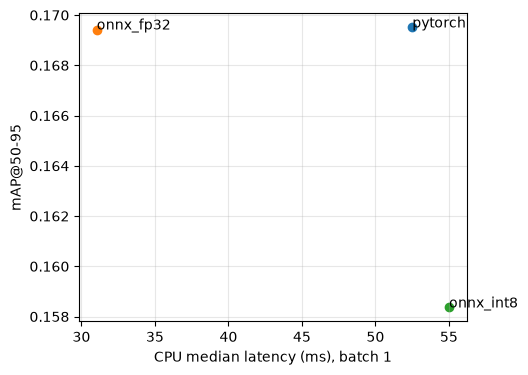

In [6]:
acc = det_df[det_df['class'] == 'all'].set_index('model')['map50_95']
plt.figure(figsize=(5, 4))
for k in lat.index:
    plt.scatter(lat.loc[k, 'median_ms'], acc[k]); plt.annotate(k, (lat.loc[k, 'median_ms'], acc[k]))
plt.xlabel('CPU median latency (ms), batch 1'); plt.ylabel('mAP@50-95'); plt.grid(alpha=.3)
plt.savefig('reports/accuracy_vs_latency.png', dpi=150, bbox_inches='tight')

## Robustness: blur, noise, low light at three severities
Corrupted copies of the 548 val images, labels copied, validated with `best.pt` on the GPU.

In [7]:
SRC = Path('data/VisDrone')
def blur(im, s):  return cv2.GaussianBlur(im, (0, 0), s)
def noise(im, s): return np.clip(im + np.random.default_rng(0).normal(0, s, im.shape), 0, 255).astype(np.uint8)
def dark(im, g):  return (255 * (im / 255.0) ** g * (1 / g ** 0.5)).clip(0, 255).astype(np.uint8)
CONDS = {f'{n}_{i+1}': (f, p) for n, f, ps in [('blur', blur, [1.5, 3, 5]), ('noise', noise, [10, 25, 50]),
                                                ('lowlight', dark, [1.5, 2.2, 3.0])] for i, p in enumerate(ps)}
imgs = sorted((SRC/'images/val').glob('*.jpg'))
print(len(imgs), 'val images')
for name, (f, p) in CONDS.items():
    d = Path('data/robustness')/name; (d/'images').mkdir(parents=True, exist_ok=True)
    shutil.copytree(SRC/'labels/val', d/'labels', dirs_exist_ok=True)
    for q in imgs: cv2.imwrite(str(d/'images'/q.name), f(cv2.imread(str(q)), p))
    names = YOLO(BEST).names
    (Path('data/robustness')/f'{name}.yaml').write_text(
        f"path: {d.resolve().as_posix()}\ntrain: images\nval: images\nnames:\n" + ''.join(f"  {i}: {n}\n" for i, n in names.items()))
# look at them before trusting numbers
im = cv2.imread(str(imgs[0])); sheet = [cv2.resize(im, (320, 240))] + [cv2.resize(cv2.imread(str(Path('data/robustness')/n/'images'/imgs[0].name)), (320, 240)) for n in CONDS]
cv2.imwrite('reports/corruption_examples.png', np.vstack([np.hstack(sheet[:5]), np.hstack(sheet[5:])]))

548 val images


True

In [8]:
def rob(weights, device):
    rows = [{'condition': 'clean', 'map50_95': YOLO(weights, task='detect').val(data='VisDrone.yaml', imgsz=640, device=device, plots=False, verbose=False).box.map}]
    for n in CONDS:
        rows.append({'condition': n, 'map50_95': YOLO(weights, task='detect').val(data=f'data/robustness/{n}.yaml', imgsz=640, device=device, plots=False, verbose=False).box.map})
    df = pd.DataFrame(rows); df['drop_from_clean'] = df.map50_95.iloc[0] - df.map50_95; return df

robust = rob(BEST, 0); robust.to_csv('reports/robustness.csv', index=False); robust

Ultralytics 8.4.212  Python-3.11.9 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)


Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 1605.8±814.8 MB/s, size: 168.6 KB)


val: Scanning D:\Projects\computer-vision project\data\VisDrone\labels\val.cache... 548 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 548/548  0.0s

WARNING Dataset images contain up to 317 objects (val=317), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=317 to match the observed maximum.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 1/35 64.7s/it 19.4s<36:41

... (375 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 1.5it/s 22.6s

                   all        548      38759      0.379      0.254      0.231      0.126


Speed: 0.6ms preprocess, 2.1ms inference, 0.0ms loss, 1.6ms postprocess per image


,condition,map50_95,drop_from_clean
0,clean,0.169506,0.000000
1,blur_1,0.157771,0.011735
2,blur_2,0.104758,0.064748
3,blur_3,0.047308,0.122197
4,noise_1,0.152738,0.016768
5,noise_2,0.105604,0.063902
6,noise_3,0.031998,0.137507
7,lowlight_1,0.163849,0.005657
8,lowlight_2,0.147787,0.021719
9,lowlight_3,0.125505,0.044001


Optional: the same table for the INT8 model on CPU (slow).

In [9]:
# rob(W/'best_int8.onnx', 'cpu').to_csv('reports/robustness_int8.csv', index=False)